In [ ]:
import matplotlib.pyplot as plt
from ZeroIntelligenceLOB import ZeroIntelligenceLOB as LOB
import math
import numpy as np

In [44]:
# calibrate these parameters
alpha = 0.5 # limit order arrival rate (shares/price/time)
mu = 0.2 # market order arrival rate (shares/time)
delta = 0.001 # order cancellation rate (1/time)
dp = 0.00001 # price increment (price)
sigma = 1 # constant order size (shares)

In [45]:
lob = LOB(alpha, mu, delta, sigma, dp)

In [ ]:
n_events = 100000
record_every = 500 # record every 500 events

for i in range(n_events):
    lob.next_event()
    if i % record_every == 0:
        lob.record_state()

In [49]:
spreads = [s["spread"] for s in lob.history if not math.isnan(s["spread"])]

if lob.epsilon >= 0.1:
    epsilon_regime = "Large"
elif lob.epsilon >= 0.001:
    epsilon_regime = "Medium"
else:
    epsilon_regime = "Small"

print(f"Dimensionless epsilon: {lob.epsilon} ({epsilon_regime} regime)")
print(f"Mean spread: {sum(spreads) / len(spreads)}")
print(f"Final mid-price: {lob.history[-1]['mid_price']}")
print(f"{n_events} events simulated")

Dimensionless epsilon: 0.01 (Medium regime)
Mean spread: 0.0004675889978944142
Final mid-price: 4.870535
100000 events simulated


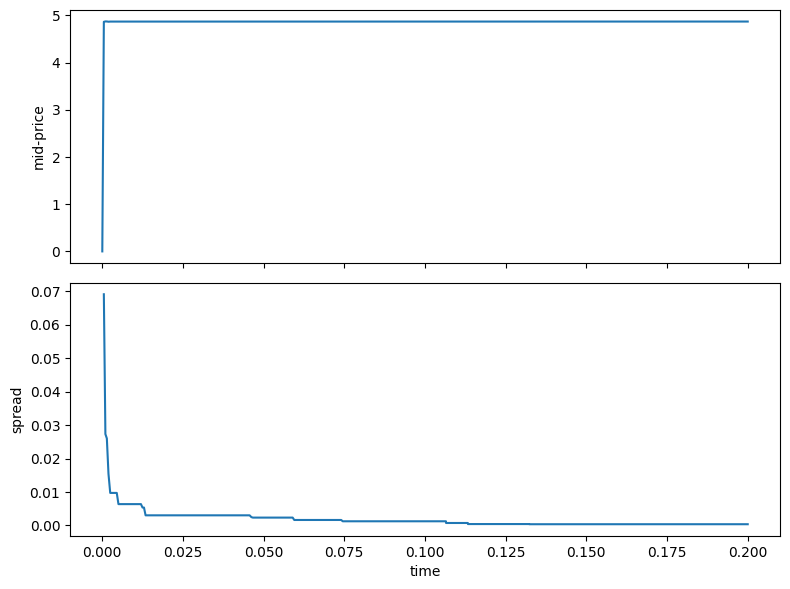

In [50]:
mid = [s["mid_price"] for s in lob.history]

spreads = np.array([s["spread"] for s in lob.history])
times   = np.array([s["time"]   for s in lob.history])
mask = ~np.isnan(spreads)


fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8,6))
ax[0].plot(times, mid)
ax[0].set_ylabel("mid-price")
ax[1].plot(times[mask], spreads[mask])
ax[1].set_ylabel("spread")
ax[1].set_xlabel("time")
plt.tight_layout()
plt.show()